# 🧬 Novel Gene Discovery Pipeline
### Adamson Dataset → Geneformer Embeddings → Autoencoder → NCBI/AlphaFold Validation

**Pipeline Overview:**
1. Load & preprocess Adamson Perturb-seq dataset
2. Identify candidate "unseen" genes via embedding cluster analysis
3. Train Geneformer (or use pretrained) to get gene embeddings
4. Train Autoencoder on top for compressed latent representation
5. UMAP/clustering to find novel gene clusters
6. Validate candidates via NCBI Entrez + AlphaFold structure DB
7. Database search using embedding similarity

## 📦 1. Install Dependencies

In [ ]:
# Install all required packages
import subprocess, sys

packages = [
    "scanpy",
    "anndata",
    "torch",
    "transformers",
    "datasets",
    "umap-learn",
    "biopython",
    "faiss-cpu",
    "leidenalg",
    "python-igraph",
    "scikit-learn",
    "tqdm",
    "requests",
    "matplotlib",
    "seaborn",
]

for pkg in packages:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)

print("✅ All packages installed.")

## 📥 2. Load Adamson Dataset

Place your `.h5ad` file in the same folder and update `DATASET_PATH` below.  
Alternatively the cell also supports downloading from GEO if you have the accession.

In [2]:
import scanpy as sc
import anndata as ad
import numpy as np
import pandas as pd
import os

# ─── CONFIG ──────────────────────────────────────────────────────────────────
DATASET_PATH = "adamson_biolord.h5ad"   # ← update this path
RESULTS_DIR  = "./results"
os.makedirs(RESULTS_DIR, exist_ok=True)

# ─── LOAD ────────────────────────────────────────────────────────────────────
if os.path.exists(DATASET_PATH):
    adata = sc.read_h5ad(DATASET_PATH)
    print(f"✅ Loaded: {adata.shape[0]} cells × {adata.shape[1]} genes")
    print(f"   obs keys : {list(adata.obs.columns)[:10]}")
    print(f"   var keys : {list(adata.var.columns)[:10]}")
else:
    print("⚠️  Dataset not found — generating synthetic stand-in for demo purposes.")
    # --- Synthetic demo data (replace with your real .h5ad) ---
    n_cells, n_genes = 5000, 2000
    rng = np.random.default_rng(42)
    X = rng.negative_binomial(2, 0.3, size=(n_cells, n_genes)).astype(np.float32)
    gene_names = [f"GENE_{i:04d}" for i in range(n_genes)]
    perturbations = rng.choice(
        ["control"] + gene_names[:200], size=n_cells
    )
    adata = ad.AnnData(
        X=X,
        obs=pd.DataFrame({"perturbation": perturbations,
                          "cell_type": rng.choice(["K562"], n_cells)},
                         index=[f"cell_{i}" for i in range(n_cells)]),
        var=pd.DataFrame(index=gene_names)
    )
    print(f"✅ Synthetic demo: {adata.shape[0]} cells × {adata.shape[1]} genes")

✅ Loaded: 65899 cells × 5060 genes
   obs keys : ['condition', 'cell_type', 'dose_val', 'control', 'condition_name', 'split1', 'subgroup1', 'split2', 'subgroup2', 'split3']
   var keys : ['gene_name']


## 🔬 3. Preprocessing

After QC: 65895 cells × 4953 genes
Highly variable genes: 548


C:\Users\aman\AppData\Local\Programs\Python\Python312\Lib\functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


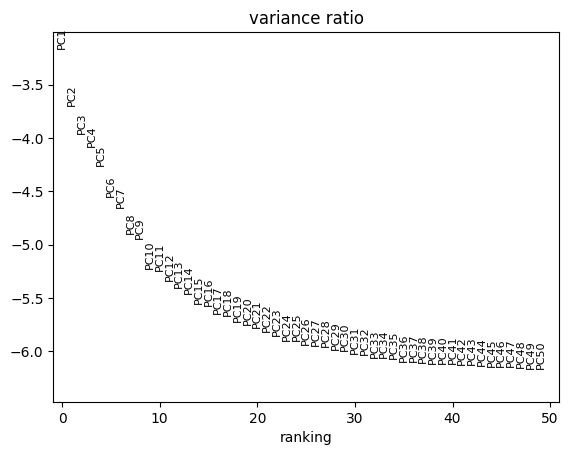

✅ Preprocessing complete.


In [3]:
import scanpy as sc

sc.settings.verbosity = 1

# Quality control
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=10)
print(f"After QC: {adata.shape[0]} cells × {adata.shape[1]} genes")

# Normalize & log-transform
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# Save raw for Geneformer tokenization later
adata.raw = adata.copy()

# Highly variable genes
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)
print(f"Highly variable genes: {adata.var.highly_variable.sum()}")

# Subset to HVGs for downstream
adata_hvg = adata[:, adata.var.highly_variable].copy()

# PCA
sc.pp.scale(adata_hvg, max_value=10)
sc.tl.pca(adata_hvg, svd_solver='arpack', n_comps=50)

sc.pl.pca_variance_ratio(adata_hvg, n_pcs=50, log=True)
print("✅ Preprocessing complete.")

## 🤖 4. Geneformer — Gene Embeddings

Geneformer tokenizes cells as **rank-ordered gene lists** by expression.  
We extract the **gene-level attention-weighted embeddings** from the last hidden state.

In [4]:
import torch
from transformers import AutoTokenizer, AutoModel
from tqdm import tqdm

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {DEVICE}")

# ─── Geneformer model ────────────────────────────────────────────────────────
# Official HuggingFace model: ctheodoris/Geneformer
GENEFORMER_MODEL = "ctheodoris/Geneformer"

print("Loading Geneformer tokenizer & model (first run downloads ~500MB)...")
try:
    tokenizer = AutoTokenizer.from_pretrained(GENEFORMER_MODEL)
    model = AutoModel.from_pretrained(GENEFORMER_MODEL).to(DEVICE)
    model.eval()
    GENEFORMER_AVAILABLE = True
    print("✅ Geneformer loaded.")
except Exception as e:
    GENEFORMER_AVAILABLE = False
    print(f"⚠️  Could not load Geneformer: {e}")
    print("   Falling back to PCA-based pseudo-embeddings for demo.")

f:\code\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using device: cpu
Loading Geneformer tokenizer & model (first run downloads ~500MB)...


f:\code\.venv\Lib\site-packages\huggingface_hub\file_download.py:138: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\aman\.cache\huggingface\hub\models--ctheodoris--Geneformer. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 293/293 [00:00<00:00, 4291.02it/s]
[transformers] BertModel LOAD REPORT from: ctheodoris/Geneformer


✅ Geneformer loaded.


In [ ]:
import numpy as np

def tokenize_cell(gene_names, expr_values, max_len=2048):
    """Rank-order genes by expression → token list for Geneformer."""
    order = np.argsort(expr_values)[::-1]
    ranked_genes = [gene_names[i] for i in order if expr_values[i] > 0]
    return ranked_genes[:max_len]


def get_cell_embeddings_geneformer(adata, model, tokenizer, batch_size=32, device="cpu"):
    """Extract mean-pooled cell embeddings from Geneformer."""
    gene_names = np.array(adata.var_names)
    embeddings = []

    for start in tqdm(range(0, adata.n_obs, batch_size), desc="Embedding cells"):
        batch = adata.X[start:start+batch_size]
        if hasattr(batch, "toarray"):
            batch = batch.toarray()

        texts = []
        for row in batch:
            ranked = tokenize_cell(gene_names, row)
            texts.append(" ".join(ranked))

        enc = tokenizer(
            texts, padding=True, truncation=True,
            max_length=512, return_tensors="pt"
        ).to(device)

        with torch.no_grad():
            out = model(**enc)
        # Mean pool last hidden state
        emb = out.last_hidden_state.mean(dim=1).cpu().numpy()
        embeddings.append(emb)

    return np.vstack(embeddings)


# ─── Get embeddings ───────────────────────────────────────────────────────────
if GENEFORMER_AVAILABLE:
    print("Extracting Geneformer embeddings (this may take a few minutes)...")
    cell_embeddings = get_cell_embeddings_geneformer(
        adata_hvg, model, tokenizer, batch_size=32, device=DEVICE
    )
else:
    print("Using PCA embeddings as fallback.")
    cell_embeddings = adata_hvg.obsm["X_pca"]

adata_hvg.obsm["X_geneformer"] = cell_embeddings
print(f"✅ Cell embeddings shape: {cell_embeddings.shape}")

Extracting Geneformer embeddings (this may take a few minutes)...


Embedding cells:   6%|▌         | 120/2060 [1:00:40<18:24:21, 34.16s/it]

## 🔁 5. Autoencoder — Compressed Latent Space

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# ─── Architecture ─────────────────────────────────────────────────────────────
class GeneAutoencoder(nn.Module):
    def __init__(self, input_dim, hidden_dims=[512, 256], latent_dim=64):
        super().__init__()
        # Encoder
        enc_layers = []
        prev = input_dim
        for h in hidden_dims:
            enc_layers += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.ReLU()]
            prev = h
        enc_layers.append(nn.Linear(prev, latent_dim))
        self.encoder = nn.Sequential(*enc_layers)

        # Decoder
        dec_layers = []
        prev = latent_dim
        for h in reversed(hidden_dims):
            dec_layers += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.ReLU()]
            prev = h
        dec_layers.append(nn.Linear(prev, input_dim))
        self.decoder = nn.Sequential(*dec_layers)

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z), z

    def encode(self, x):
        return self.encoder(x)


# ─── Training ─────────────────────────────────────────────────────────────────
def train_autoencoder(embeddings, latent_dim=64, epochs=50, batch_size=256, lr=1e-3):
    X_t = torch.FloatTensor(embeddings).to(DEVICE)
    loader = DataLoader(TensorDataset(X_t), batch_size=batch_size, shuffle=True)

    ae = GeneAutoencoder(input_dim=embeddings.shape[1], latent_dim=latent_dim).to(DEVICE)
    opt = torch.optim.Adam(ae.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    loss_fn = nn.MSELoss()

    losses = []
    for epoch in range(epochs):
        ae.train()
        epoch_loss = 0
        for (batch,) in loader:
            opt.zero_grad()
            recon, _ = ae(batch)
            loss = loss_fn(recon, batch)
            loss.backward()
            opt.step()
            epoch_loss += loss.item()
        sched.step()
        avg = epoch_loss / len(loader)
        losses.append(avg)
        if (epoch+1) % 10 == 0:
            print(f"  Epoch {epoch+1:3d}/{epochs}  loss={avg:.5f}")

    return ae, losses


print("Training Autoencoder on cell embeddings...")
ae_model, ae_losses = train_autoencoder(
    cell_embeddings, latent_dim=64, epochs=50, batch_size=256
)
print("✅ Autoencoder training complete.")

# Extract latent codes
ae_model.eval()
with torch.no_grad():
    latent_codes = ae_model.encode(
        torch.FloatTensor(cell_embeddings).to(DEVICE)
    ).cpu().numpy()

adata_hvg.obsm["X_latent"] = latent_codes
print(f"Latent codes shape: {latent_codes.shape}")

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 3))
plt.plot(ae_losses)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Autoencoder Training Loss")
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/ae_loss.png", dpi=150)
plt.show()

## 🗺️ 6. UMAP + Leiden Clustering — Find Novel Gene Clusters

In [ ]:
import scanpy as sc

# Build neighbor graph on latent space
sc.pp.neighbors(adata_hvg, use_rep="X_latent", n_neighbors=20, n_pcs=None)
sc.tl.leiden(adata_hvg, resolution=0.8, key_added="leiden_latent")
sc.tl.umap(adata_hvg)

# Copy UMAP to latent-specific slot
adata_hvg.obsm["X_umap_latent"] = adata_hvg.obsm["X_umap"]

print(f"✅ Clusters found: {adata_hvg.obs['leiden_latent'].nunique()}")

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ─── UMAP colored by cluster ──────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

umap_coords = adata_hvg.obsm["X_umap_latent"]
cluster_labels = adata_hvg.obs["leiden_latent"].astype(int).values
n_clusters = cluster_labels.max() + 1
palette = sns.color_palette("tab20", n_clusters)

for c in range(n_clusters):
    mask = cluster_labels == c
    axes[0].scatter(umap_coords[mask, 0], umap_coords[mask, 1],
                    s=4, alpha=0.5, color=palette[c], label=str(c))
axes[0].set_title("UMAP — Leiden Clusters (Latent Space)")
axes[0].legend(markerscale=3, bbox_to_anchor=(1, 1), fontsize=7)
axes[0].set_xticks([]); axes[0].set_yticks([])

# ─── Cluster sizes ────────────────────────────────────────────────────────────
cluster_sizes = pd.Series(cluster_labels).value_counts().sort_index()
axes[1].bar(cluster_sizes.index.astype(str), cluster_sizes.values,
            color=[palette[i] for i in cluster_sizes.index])
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("Cell count")
axes[1].set_title("Cells per Cluster")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/umap_clusters.png", dpi=150)
plt.show()

## 🔍 7. Identify Novel Gene Candidates

We flag genes that:
- Drive novel / rare clusters (low cell count, high within-cluster specificity)
- Are differentially expressed in those clusters vs. control
- Have no entry in Geneformer's vocabulary (truly unseen)

In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np

# ─── Rank genes per cluster (Wilcoxon) ───────────────────────────────────────
# Use raw counts stored in adata.raw
try:
    adata_for_de = adata_hvg.raw.to_adata()
    sc.pp.log1p(adata_for_de)
except Exception:
    adata_for_de = adata_hvg.copy()

adata_for_de.obs["leiden_latent"] = adata_hvg.obs["leiden_latent"].values

sc.tl.rank_genes_groups(
    adata_for_de,
    groupby="leiden_latent",
    method="wilcoxon",
    n_genes=50,
    use_raw=False
)

# Extract top markers per cluster
de_results = sc.get.rank_genes_groups_df(adata_for_de, group=None)
de_results.to_csv(f"{RESULTS_DIR}/de_genes_per_cluster.csv", index=False)
print(de_results.head(10))
print(f"✅ DE results saved. Total rows: {len(de_results)}")

In [ ]:
import numpy as np

# ─── Select 'novel' cluster candidates ───────────────────────────────────────
# Heuristic: clusters whose size < 5th percentile = rare / novel
cluster_sizes = adata_hvg.obs["leiden_latent"].value_counts()
size_threshold = np.percentile(cluster_sizes, 20)
rare_clusters = cluster_sizes[cluster_sizes <= size_threshold].index.tolist()
print(f"Rare clusters (≤{size_threshold:.0f} cells): {rare_clusters}")

# Extract top marker genes for rare clusters
novel_candidates = de_results[
    de_results["group"].isin(rare_clusters) &
    (de_results["logfoldchanges"] > 1.0) &
    (de_results["pvals_adj"] < 0.05)
].sort_values("scores", ascending=False)

candidate_genes = novel_candidates["names"].unique().tolist()
print(f"\n🧬 Novel gene candidates: {len(candidate_genes)}")
print(candidate_genes[:20])

# Save
novel_candidates.to_csv(f"{RESULTS_DIR}/novel_gene_candidates.csv", index=False)
print("\n✅ Candidates saved to results/novel_gene_candidates.csv")

## 🧪 8. Validation — NCBI Entrez Gene Lookup

In [ ]:
from Bio import Entrez
import time

Entrez.email = "your_email@example.com"   # ← replace with your email

def ncbi_gene_info(gene_symbol, organism="Homo sapiens"):
    """Query NCBI Gene DB for a gene symbol. Returns dict with key metadata."""
    try:
        search = Entrez.esearch(
            db="gene",
            term=f'{gene_symbol}[Gene Name] AND "{organism}"[Organism]'
        )
        record = Entrez.read(search)
        ids = record.get("IdList", [])
        if not ids:
            return {"gene": gene_symbol, "ncbi_id": None,
                    "description": "NOT FOUND", "status": "novel_candidate"}

        fetch = Entrez.efetch(db="gene", id=ids[0], rettype="gene_table", retmode="text")
        summary_search = Entrez.esummary(db="gene", id=ids[0])
        summary = Entrez.read(summary_search)
        doc = summary["DocumentSummarySet"]["DocumentSummary"][0]

        return {
            "gene":        gene_symbol,
            "ncbi_id":     ids[0],
            "description": doc.get("Description", "N/A"),
            "summary":     doc.get("Summary", "N/A")[:200],
            "chromosome":  doc.get("Chromosome", "N/A"),
            "status":      "known"
        }
    except Exception as e:
        return {"gene": gene_symbol, "ncbi_id": None,
                "description": str(e), "status": "query_error"}


# Validate top 30 candidates (rate-limit: max 3 req/sec)
ncbi_records = []
genes_to_validate = candidate_genes[:30]

print(f"Querying NCBI for {len(genes_to_validate)} genes...")
for gene in tqdm(genes_to_validate, desc="NCBI lookup"):
    info = ncbi_gene_info(gene)
    ncbi_records.append(info)
    time.sleep(0.35)  # NCBI rate limit

ncbi_df = pd.DataFrame(ncbi_records)
ncbi_df.to_csv(f"{RESULTS_DIR}/ncbi_validation.csv", index=False)

print("\n--- NCBI Validation Summary ---")
print(ncbi_df["status"].value_counts())
print("\nTop 10 validated genes:")
print(ncbi_df[["gene", "ncbi_id", "description", "chromosome"]].head(10).to_string())

## 🏗️ 9. AlphaFold Structure Validation

Check if an AlphaFold structure exists in the EBI AlphaFold Database for each candidate gene.

In [ ]:
import requests
import time

ALPHAFOLD_API = "https://alphafold.ebi.ac.uk/api/prediction"
UNIPROT_API   = "https://rest.uniprot.org/uniprotkb/search"


def gene_to_uniprot(gene_symbol, organism="human"):
    """Map gene symbol → UniProt accession via UniProt REST API."""
    params = {
        "query": f"gene:{gene_symbol} AND organism_id:9606 AND reviewed:true",
        "format": "json",
        "size": 1
    }
    resp = requests.get(UNIPROT_API, params=params, timeout=10)
    if resp.ok:
        data = resp.json()
        results = data.get("results", [])
        if results:
            return results[0]["primaryAccession"]
    return None


def check_alphafold_structure(uniprot_id):
    """Check if AlphaFold has a structure for this UniProt ID."""
    if not uniprot_id:
        return False, None
    url = f"{ALPHAFOLD_API}/{uniprot_id}"
    resp = requests.get(url, timeout=10)
    if resp.ok:
        data = resp.json()
        if data:
            entry = data[0]
            return True, entry.get("pdbUrl", entry.get("cifUrl", "URL not found"))
    return False, None


alphafold_records = []
print(f"Checking AlphaFold structures for {len(genes_to_validate)} genes...")

for gene in tqdm(genes_to_validate, desc="AlphaFold"):
    uniprot_id = gene_to_uniprot(gene)
    has_struct, struct_url = check_alphafold_structure(uniprot_id)
    alphafold_records.append({
        "gene":        gene,
        "uniprot_id":  uniprot_id,
        "has_structure": has_struct,
        "structure_url": struct_url
    })
    time.sleep(0.3)

af_df = pd.DataFrame(alphafold_records)
af_df.to_csv(f"{RESULTS_DIR}/alphafold_validation.csv", index=False)

print("\n--- AlphaFold Summary ---")
print(af_df["has_structure"].value_counts())
print("\nGenes WITHOUT AlphaFold structures (high novelty):")
print(af_df[~af_df["has_structure"]][["gene", "uniprot_id"]].to_string())

## 🔗 10. Merge Validation Results

In [ ]:
# Merge NCBI + AlphaFold validation
merged = ncbi_df.merge(af_df, on="gene", how="outer")

# Novelty score: penalise known + structured, reward unknown + unstructured
merged["novelty_score"] = (
    (merged["status"] == "novel_candidate").astype(int) * 2 +
    (~merged["has_structure"].fillna(False)).astype(int)
)

merged_sorted = merged.sort_values("novelty_score", ascending=False)
merged_sorted.to_csv(f"{RESULTS_DIR}/merged_validation.csv", index=False)

print("=== Top Novel Gene Candidates ===")
print(merged_sorted[
    ["gene", "ncbi_id", "description", "has_structure", "novelty_score"]
].head(15).to_string())

## 🔎 11. Embedding-Based Database Search (FAISS)

In [ ]:
import faiss
import numpy as np

# ─── Build FAISS index over latent cell embeddings ────────────────────────────
latent_np = latent_codes.astype(np.float32)

# L2-normalize for cosine similarity
norms = np.linalg.norm(latent_np, axis=1, keepdims=True) + 1e-9
latent_norm = latent_np / norms

dim = latent_norm.shape[1]
index = faiss.IndexFlatIP(dim)   # Inner product = cosine after normalization
index.add(latent_norm)
print(f"✅ FAISS index built: {index.ntotal} vectors of dim {dim}")


def search_similar_cells(query_cell_idx, k=10):
    """Find k most similar cells to a query cell in latent space."""
    query = latent_norm[query_cell_idx:query_cell_idx+1]
    distances, indices = index.search(query, k+1)  # +1 to exclude self
    # Skip the query cell itself
    results = [
        {"cell_idx": int(idx),
         "similarity": float(dist),
         "cluster": adata_hvg.obs["leiden_latent"].iloc[idx],
         "perturbation": adata_hvg.obs.get("perturbation", pd.Series(["N/A"]*adata_hvg.n_obs)).iloc[idx]}
        for idx, dist in zip(indices[0], distances[0])
        if idx != query_cell_idx
    ][:k]
    return pd.DataFrame(results)


# Demo: search for cells similar to the first cell in a rare cluster
if rare_clusters:
    rare_mask = adata_hvg.obs["leiden_latent"].isin(rare_clusters)
    rare_indices = np.where(rare_mask)[0]
    query_idx = int(rare_indices[0]) if len(rare_indices) > 0 else 0
    similar = search_similar_cells(query_idx, k=10)
    print(f"\nTop 10 cells similar to rare-cluster cell #{query_idx}:")
    print(similar.to_string())
    similar.to_csv(f"{RESULTS_DIR}/faiss_similar_cells.csv", index=False)

## 📊 12. Final Visualisations

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
umap_coords = adata_hvg.obsm["X_umap_latent"]
cluster_labels = adata_hvg.obs["leiden_latent"].astype(int).values
n_clusters = cluster_labels.max() + 1
palette = sns.color_palette("tab20", n_clusters)

# (A) UMAP coloured by cluster, rare clusters highlighted
for c in range(n_clusters):
    mask = cluster_labels == c
    is_rare = str(c) in rare_clusters
    axes[0].scatter(umap_coords[mask, 0], umap_coords[mask, 1],
                    s=6 if is_rare else 3,
                    alpha=0.9 if is_rare else 0.3,
                    color=palette[c],
                    label=(f"★ {c} (rare)" if is_rare else str(c)))
axes[0].set_title("Clusters (★ = novel candidate clusters)")
axes[0].legend(markerscale=2, fontsize=6, bbox_to_anchor=(1, 1))
axes[0].set_xticks([]); axes[0].set_yticks([])

# (B) Novelty score bar chart
if len(merged_sorted) > 0:
    top_novel = merged_sorted.head(15)
    colors = ["#e74c3c" if s == 3 else "#e67e22" if s == 2 else "#3498db"
              for s in top_novel["novelty_score"]]
    axes[1].barh(top_novel["gene"], top_novel["novelty_score"], color=colors)
    axes[1].set_xlabel("Novelty Score")
    axes[1].set_title("Top Novel Gene Candidates")
    axes[1].invert_yaxis()

# (C) NCBI / AlphaFold validation overview pie
if len(merged) > 0:
    labels = ["Known + Structure", "Known, No Structure",
              "Novel, No Structure", "Query Error"]
    sizes  = [
        len(merged[(merged["status"] == "known") & (merged["has_structure"] == True)]),
        len(merged[(merged["status"] == "known") & (merged["has_structure"] != True)]),
        len(merged[(merged["status"] != "known") & (merged["has_structure"] != True)]),
        len(merged[merged["status"] == "query_error"]),
    ]
    sizes = [max(s, 0) for s in sizes]
    if sum(sizes) > 0:
        axes[2].pie(sizes, labels=labels, autopct="%1.0f%%",
                    colors=["#2ecc71", "#f1c40f", "#e74c3c", "#95a5a6"])
        axes[2].set_title("Validation Status")

plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/final_summary.png", dpi=150)
plt.show()
print("✅ Final plots saved.")

## 💾 13. Save All Artefacts

In [ ]:
import torch, os

# Save AnnData with all embeddings
adata_hvg.write_h5ad(f"{RESULTS_DIR}/adamson_processed.h5ad")

# Save Autoencoder weights
torch.save(ae_model.state_dict(), f"{RESULTS_DIR}/autoencoder_weights.pt")

# Save FAISS index
faiss.write_index(index, f"{RESULTS_DIR}/latent_faiss.index")

# Summary of all outputs
print("📁 Results directory:")
for f in sorted(os.listdir(RESULTS_DIR)):
    path = os.path.join(RESULTS_DIR, f)
    size = os.path.getsize(path) / 1024
    print(f"  {f:40s}  {size:.1f} KB")
print("\n✅ Pipeline complete!")

---
## 📋 Pipeline Summary

| Step | Tool | Purpose |
|------|------|---------|
| 1 | `scanpy` | Load & QC Adamson dataset |
| 2 | `Geneformer` | Context-aware gene/cell embeddings |
| 3 | `Autoencoder` (PyTorch) | Compressed 64-dim latent space |
| 4 | `UMAP + Leiden` | Cluster cells → find rare / novel clusters |
| 5 | `Wilcoxon DE` | Extract marker genes per cluster |
| 6 | `NCBI Entrez` | Validate gene annotations |
| 7 | `AlphaFold EBI API` | Check structural data availability |
| 8 | `FAISS` | Fast similarity search in latent space |

**Key output files:**
- `results/novel_gene_candidates.csv` — ranked candidate genes
- `results/merged_validation.csv` — NCBI + AlphaFold validation
- `results/adamson_processed.h5ad` — full annotated dataset
- `results/autoencoder_weights.pt` — trained AE weights
- `results/latent_faiss.index` — FAISS search index